IMPORTS

In [1]:
import glob
import os

import random
import h5py
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import pandas as pd
from tqdm import tqdm

import torch
import torch.nn as nn
from torch.utils.data import DataLoader

import src.loss as criterions
import Models
from src.dataset import Dataset

# import shutil
# if not os.path.isdir(DATASET_PATH):
#     raise FileNotFoundError(
#         f"There is no folder at {DATASET_PATH}.\n"
#         "Copy the real path from the Input panel on the right: expand the "
#         "competition data, hover over its folder, and click the copy-path icon."
#     )

# shutil.copy(f"{DATASET_PATH}/metric.py", "metric.py")
# from metric import rle_encode, rle_decode, global_dice, write_submission

from src.metric import global_dice, write_submission

SETTINGS

In [2]:
SESSION_ID = "model01_new_scheduler_2"

# Seed
SEED = 2006
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)                     # seeds the GPU as well
torch.backends.cudnn.benchmark = False      # the same algorithms on every run
torch.backends.cudnn.deterministic = True

def seed_worker(worker_id):
    worker_seed = torch.initial_seed() % 2**32
    np.random.seed(worker_seed)
    random.seed(worker_seed)

# Device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Paths
DATASET_PATH = "/home/dinis/Desktop/Universidade/Cadeiras/Ano4-Q1/AE4353 Artificial Intelligence for Aerospace Control and Operations/Competition/Data/ae4353-2026"

OUTPUT_BASE_PATH = "/home/dinis/Desktop/Universidade/Cadeiras/Ano4-Q1/AE4353 Artificial Intelligence for Aerospace Control and Operations/Competition/Output"

# Dataset
BATCH_SIZE = 8
NUM_WORKERS = 4
OVERFIT_MODE = False
OVERFIT_NUM_IMAGES = 50
VAL_SPLIT = 0.2

# Model and Training
MAX_EPOCHS = 150
THRESHOLD_RANGE = np.arange(0.1, 0.9, 0.05)
LEARNING_RATE = 1e-3
WEIGHT_DICE = 0.001
WEIGHT_DECAY = 1e-2
ETA_MIN = 1e-5

model = Models.model01.Contrail_CNN()
criterion = criterions.DiceBCELoss(weight_dice=WEIGHT_DICE)
optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=MAX_EPOCHS, eta_min=ETA_MIN)

# Plot
PLOT_INPUT = False
PLOT_OUTPUT = True

INITIALIZATION

In [3]:
OUTPUT_PATH = os.path.join(OUTPUT_BASE_PATH, SESSION_ID)

os.makedirs(OUTPUT_PATH, exist_ok=True)

train_files = sorted(glob.glob(f"{DATASET_PATH}/train_*.h5"))
test_files = sorted(glob.glob(f"{DATASET_PATH}/test_*.h5"))

DATASET LOADING

In [4]:
total_train_images = sum([len(h5py.File(f, 'r')['bands']) for f in train_files])

val_size = int(total_train_images * VAL_SPLIT)
train_size = total_train_images - val_size

# Shuffle the indices of the training images
indices = torch.randperm(total_train_images, generator=torch.Generator().manual_seed(SEED)).tolist()
val_indices = indices[:val_size]
train_indices = indices[val_size:]

full_train_dataset = Dataset(train_files, is_test=False, do_augmentation=True, seed=SEED)
full_val_dataset = Dataset(train_files, is_test=False, do_augmentation=False, seed=SEED)

if OVERFIT_MODE:
    train_dataset = torch.utils.data.Subset(full_train_dataset, range(OVERFIT_NUM_IMAGES))
    val_dataset = torch.utils.data.Subset(full_val_dataset, range(300, 300 + OVERFIT_NUM_IMAGES))
else:
    train_dataset = torch.utils.data.Subset(full_train_dataset, train_indices)
    val_dataset = torch.utils.data.Subset(full_val_dataset, val_indices)

test_dataset = Dataset(test_files, is_test=True)

g = torch.Generator()
g.manual_seed(SEED)
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    num_workers=NUM_WORKERS,
    worker_init_fn=seed_worker,
    generator=g,
    shuffle=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    num_workers=NUM_WORKERS,
    worker_init_fn=seed_worker,
    generator=torch.Generator().manual_seed(SEED),
    shuffle=False
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    num_workers=NUM_WORKERS,
    worker_init_fn=seed_worker,
    generator=torch.Generator().manual_seed(SEED),
    shuffle=True
)

if PLOT_INPUT:

    positive_indices = []
    for index in range(len(train_dataset)):
        _, mask = train_dataset[index]
        if torch.any(mask > 0):
            positive_indices.append(index)

    print(f"Found {len(positive_indices)} images containing contrails.")

    n_to_plot = min(6, len(positive_indices))

    selected_indices = positive_indices[:n_to_plot]

    fig, axes = plt.subplots(n_to_plot, 2, figsize=(10, 4 * n_to_plot))
    axes = np.atleast_2d(axes)

    for row, index in enumerate(selected_indices):
        image, mask = train_dataset[index]
        image_np = image.permute(1, 2, 0).numpy()
        mask_np = mask.squeeze(0).numpy()

        axes[row, 0].imshow(image_np)
        axes[row, 0].set_title(f"Image {index}")
        axes[row, 0].axis("off")

        axes[row, 1].imshow(image_np)
        axes[row, 1].imshow(mask_np, cmap="Reds", alpha=0.5)
        axes[row, 1].set_title("Contrail mask")
        axes[row, 1].axis("off")

    plt.tight_layout()
    plt.show()



/home/dinis/.conda/envs/AE4353/lib/python3.11/site-packages/albumentations/core/validation.py:132: UserWarning: ShiftScaleRotate is a special case of Affine transform. Please use Affine transform instead.
  original_init(self, **validated_kwargs)


TRAINING

In [5]:
model.to(device)

weighted_loss_history = []
dice_loss_history = []
bce_loss_history = []
epoch_full_history = []
learning_rate_history = []

validation_history = {
    "best_dice": [],
    "best_threshold": [],
    "false_positives": [],
    "false_negatives": [],
    "precision": [],
    "recall": []
}

best_epoch = 1
best_global_dice = 0.0
best_threshold = 0.0

for epoch in range(MAX_EPOCHS):

    # Training

    model.train()
    running_loss = 0.0
    running_dice_loss = 0.0
    running_bce_loss = 0.0

    train_loop = tqdm(train_loader, desc=f"Epoch [{epoch + 1}/{MAX_EPOCHS}] Training", leave=False)
    
    for images, masks in train_loop:
        images = images.to(device)
        masks = masks.to(device)
        optimizer.zero_grad()
        outputs = model(images)
        weighted_loss, dice_loss, bce_loss = criterion(outputs, masks)
        weighted_loss.backward()
        optimizer.step()
        running_loss += weighted_loss.item()
        running_dice_loss += dice_loss.item()
        running_bce_loss += bce_loss.item()

        train_loop.set_postfix(loss=weighted_loss.item())

    avg_loss = running_loss / len(train_loader)
    avg_dice_loss = running_dice_loss / len(train_loader)
    avg_bce_loss = running_bce_loss / len(train_loader)
    weighted_loss_history.append(avg_loss)
    dice_loss_history.append(avg_dice_loss)
    bce_loss_history.append(avg_bce_loss)

    # Validation

    model.eval()
    all_probs = []
    all_targets = []

    val_loop = tqdm(val_loader, desc=f"Epoch [{epoch + 1}/{MAX_EPOCHS}] Validation", leave=False)

    with torch.no_grad():
        for images, masks in val_loop:
            images = images.to(device)
            masks = masks.to(device)
            outputs = model(images)
            probs_original = torch.sigmoid(outputs)
            probs_hflip = torch.flip(torch.sigmoid(model(torch.flip(images, dims=[3]))), dims=[3])
            probs_vflip = torch.flip(torch.sigmoid(model(torch.flip(images, dims=[2]))), dims=[2])
            probs = (probs_original + probs_hflip + probs_vflip) / 3.0                    
            all_probs.append(probs.cpu().numpy())
            all_targets.append(masks.cpu().numpy())

    all_probs = np.concatenate(all_probs, axis=0)
    all_targets = np.concatenate(all_targets, axis=0)


    # Threshold Optimization

    best_val_dice = 0.0
    best_val_threshold = 0.0
    best_val_false_positives = 0
    best_val_false_negatives = 0
    best_val_precision = 0.0
    best_val_recall = 0.0

    # For binary operations with FP / FN
    target_bools = all_targets > 0.5 # Considered True if greater than 0.5
    total_pixels = target_bools.size


    for t in THRESHOLD_RANGE:

        thresholded_preds = (all_probs > t)
        dice_score = global_dice(thresholded_preds.astype(np.float32), all_targets)

        true_positives = int(np.sum(thresholded_preds & target_bools))
        false_positives = int(np.sum(thresholded_preds & ~target_bools))
        false_negatives = int(np.sum(~thresholded_preds & target_bools))

        precision = true_positives / (true_positives + false_positives) if (true_positives + false_positives) > 0 else 0
        recall = true_positives / (true_positives + false_negatives) if (true_positives + false_negatives) > 0 else 0

        # Store metrics
        epoch_full_history.append({
            "epoch": epoch + 1,         
            "avg_train_loss": avg_loss, 
            "avg_loss_dice": avg_dice_loss,
            "avg_loss_bce": avg_bce_loss,
            "threshold": float(t),
            "dice": float(dice_score),
            "false_positives": false_positives,
            "false_negatives": false_negatives,
            "precision": precision,
            "recall": recall,
            "learning_rate": optimizer.param_groups[0]['lr'],
        })

        if dice_score > best_val_dice:
            best_val_dice = dice_score
            best_val_threshold = t
            best_val_false_positives = false_positives
            best_val_false_negatives = false_negatives
            best_val_precision = precision
            best_val_recall = recall

    # Best values for this epoch's validation
    validation_history["best_dice"].append(best_val_dice)
    validation_history["best_threshold"].append(best_val_threshold)
    validation_history["false_positives"].append(best_val_false_positives)
    validation_history["false_negatives"].append(best_val_false_negatives)
    validation_history["precision"].append(best_val_precision)
    validation_history["recall"].append(best_val_recall)

    print(f"Epoch [{epoch + 1}/{MAX_EPOCHS}], Loss: {avg_loss:.4f}, Validation Dice: {best_val_dice:.4f}, Best Threshold: {best_val_threshold:.2f}, False Positives: {best_val_false_positives}, False Negatives: {best_val_false_negatives}, Precision: {best_val_precision:.2f}, Recall: {best_val_recall:.2f}, Dice Loss: {avg_dice_loss:.4f}, BCE Loss: {avg_bce_loss:.4f}, Learning Rate: {optimizer.param_groups[0]['lr']:.6f}")

    # Save the best model based on validation Dice score
    if best_val_dice > best_global_dice:
        best_epoch = epoch + 1
        best_global_dice = best_val_dice
        best_threshold = best_val_threshold
        checkpoint = {
            'epoch': epoch,
            'model_state_dict': model.state_dict(),
            'optimizer_state_dict': optimizer.state_dict(),
            'scheduler_state_dict': scheduler.state_dict(),
            'best_dice': best_val_dice,
            'best_threshold': best_val_threshold,
            'torch_rng_state': torch.get_rng_state(),
            'np_rng_state': np.random.get_state(),
            'python_rng_state': random.getstate(),
            'generator_state': g.get_state()
        }
        torch.save(checkpoint, os.path.join(OUTPUT_PATH, "best_checkpoint.pth"))
        print(f"--- New best model saved with Validation Dice: {best_global_dice:.4f} ---")

    learning_rate_history.append(optimizer.param_groups[0]['lr'])
    scheduler.step()


checkpoint = {
    'epoch': epoch,
    'model_state_dict': model.state_dict(),
    'optimizer_state_dict': optimizer.state_dict(),
    'scheduler_state_dict': scheduler.state_dict(),
    'best_dice': best_val_dice,
    'best_threshold': best_val_threshold,
    'torch_rng_state': torch.get_rng_state(),
    'np_rng_state': np.random.get_state(),
    'python_rng_state': random.getstate(),
    'generator_state': g.get_state()
}
torch.save(checkpoint, os.path.join(OUTPUT_PATH, "last_checkpoint.pth"))

Epoch [1/150], Loss: 0.0736, Validation Dice: 0.2077, Best Threshold: 0.10, False Positives: 315355, False Negatives: 324167, Precision: 0.21, Recall: 0.21, Dice Loss: 0.9820, BCE Loss: 0.0726, Learning Rate: 0.001000
--- New best model saved with Validation Dice: 0.2077 ---


Epoch [2/150], Loss: 0.0237, Validation Dice: 0.3117, Best Threshold: 0.10, False Positives: 248861, False Negatives: 286702, Precision: 0.33, Recall: 0.30, Dice Loss: 0.9390, BCE Loss: 0.0228, Learning Rate: 0.001000
--- New best model saved with Validation Dice: 0.3117 ---


Epoch [3/150], Loss: 0.0212, Validation Dice: 0.3378, Best Threshold: 0.20, False Positives: 210506, False Negatives: 282276, Precision: 0.37, Recall: 0.31, Dice Loss: 0.9111, BCE Loss: 0.0203, Learning Rate: 0.001000
--- New best model saved with Validation Dice: 0.3378 ---


Epoch [4/150], Loss: 0.0192, Validation Dice: 0.4014, Best Threshold: 0.15, False Positives: 296359, False Negatives: 231100, Precision: 0.37, Recall: 0.43, Dice Loss: 0.8725, BCE Loss: 0.0183, Learning Rate: 0.000999
--- New best model saved with Validation Dice: 0.4014 ---


Epoch [5/150], Loss: 0.0175, Validation Dice: 0.4302, Best Threshold: 0.20, False Positives: 203377, False Negatives: 240426, Precision: 0.45, Recall: 0.41, Dice Loss: 0.8290, BCE Loss: 0.0167, Learning Rate: 0.000998
--- New best model saved with Validation Dice: 0.4302 ---


...

Epoch [146/150], Loss: 0.0077, Validation Dice: 0.6557, Best Threshold: 0.35, False Positives: 149010, False Negatives: 136295, Precision: 0.65, Recall: 0.67, Dice Loss: 0.4632, BCE Loss: 0.0073, Learning Rate: 0.000013


Epoch [147/150], Loss: 0.0078, Validation Dice: 0.6555, Best Threshold: 0.35, False Positives: 144477, False Negatives: 138618, Precision: 0.65, Recall: 0.66, Dice Loss: 0.4718, BCE Loss: 0.0073, Learning Rate: 0.000012


Epoch [148/150], Loss: 0.0078, Validation Dice: 0.6555, Best Threshold: 0.35, False Positives: 146251, False Negatives: 137756, Precision: 0.65, Recall: 0.66, Dice Loss: 0.4666, BCE Loss: 0.0073, Learning Rate: 0.000011


Epoch [149/150], Loss: 0.0078, Validation Dice: 0.6553, Best Threshold: 0.35, False Positives: 148280, False Negatives: 136918, Precision: 0.65, Recall: 0.66, Dice Loss: 0.4666, BCE Loss: 0.0073, Learning Rate: 0.000010


Epoch [150/150], Loss: 0.0078, Validation Dice: 0.6550, Best Threshold: 0.35, False Positives: 146532, False Negatives: 137947, Precision: 0.65, Recall: 0.66, Dice Loss: 0.4699, BCE Loss: 0.0073, Learning Rate: 0.000010


PLOT and ANALYSIS

Saved metrics to /home/dinis/Desktop/Universidade/Cadeiras/Ano4-Q1/AE4353 Artificial Intelligence for Aerospace Control and Operations/Competition/Output/model01_new_scheduler_2/training_validation_metrics.csv


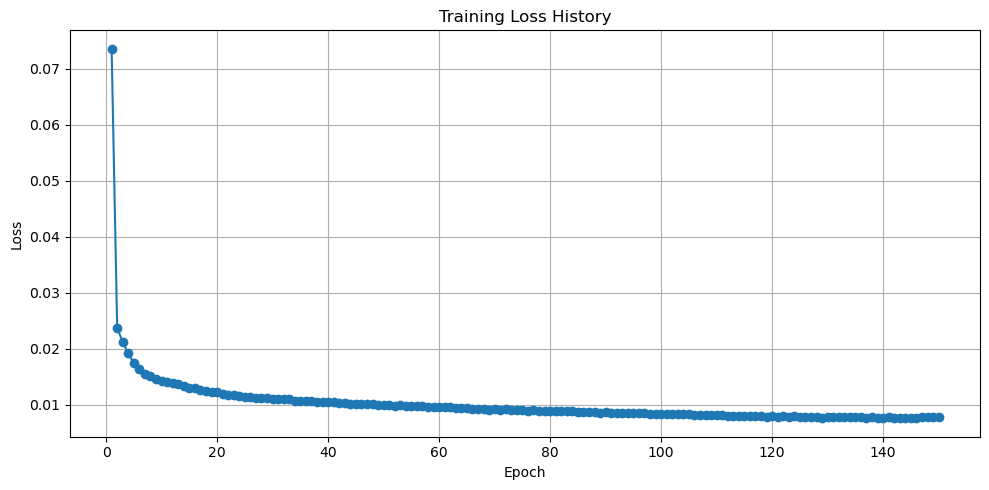

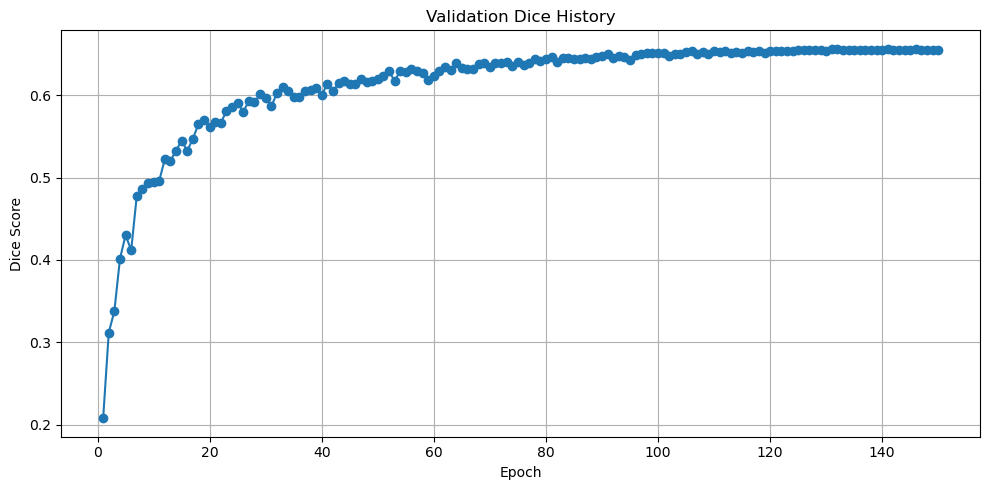

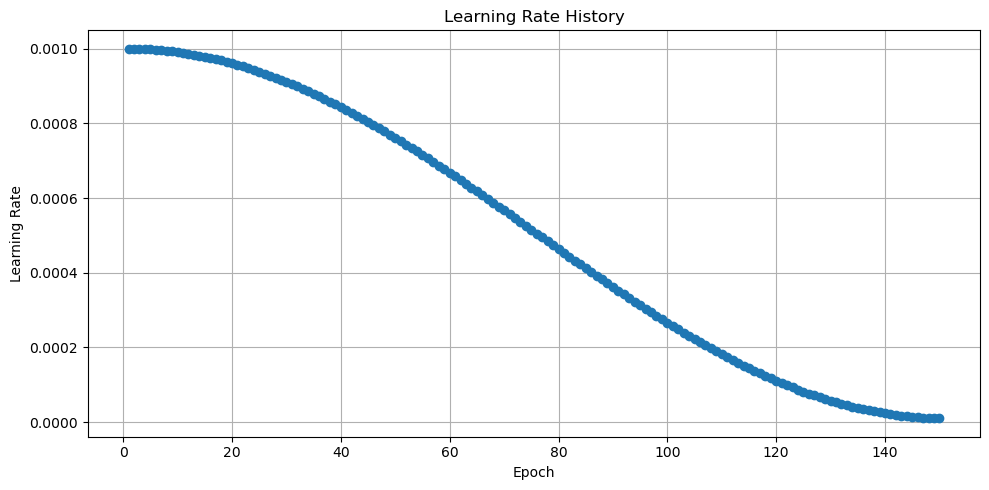

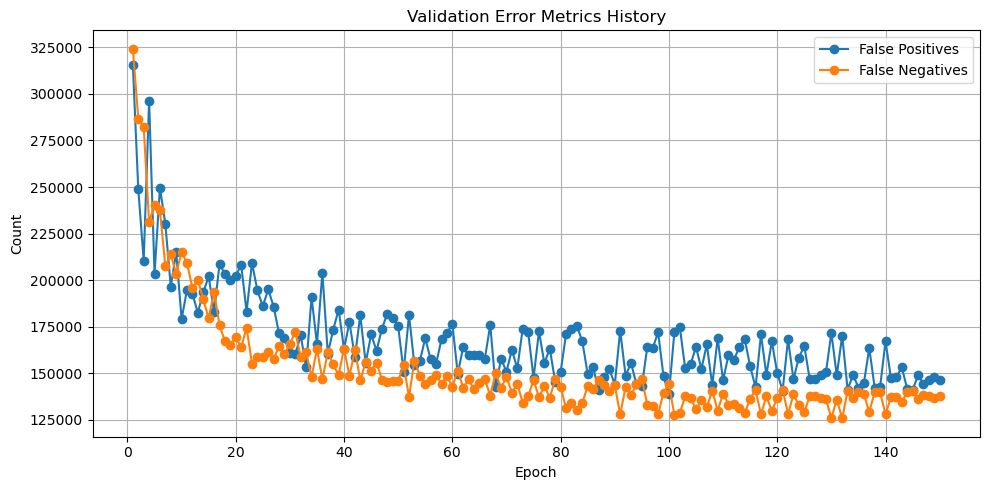

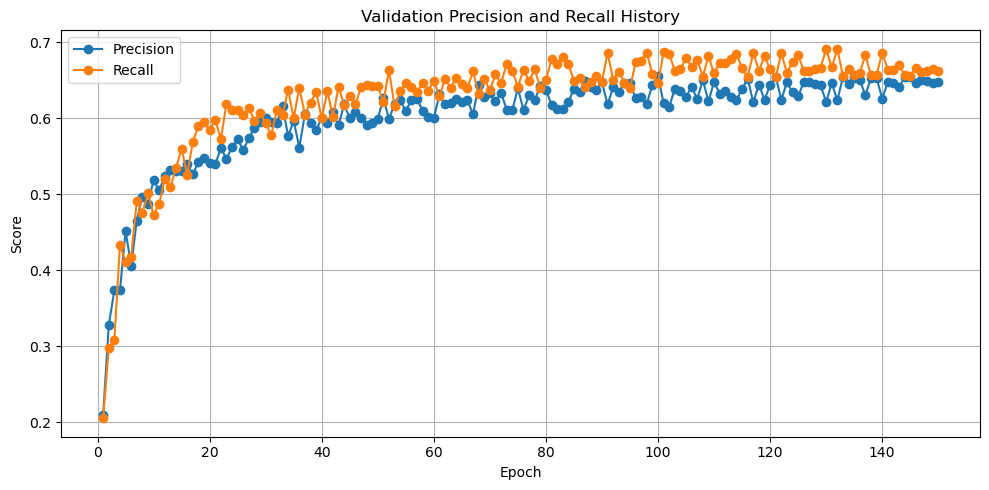

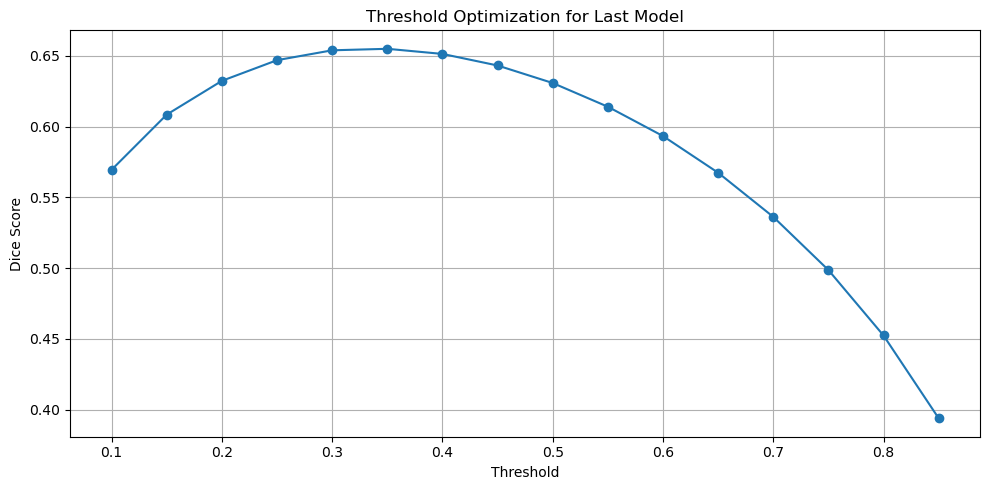

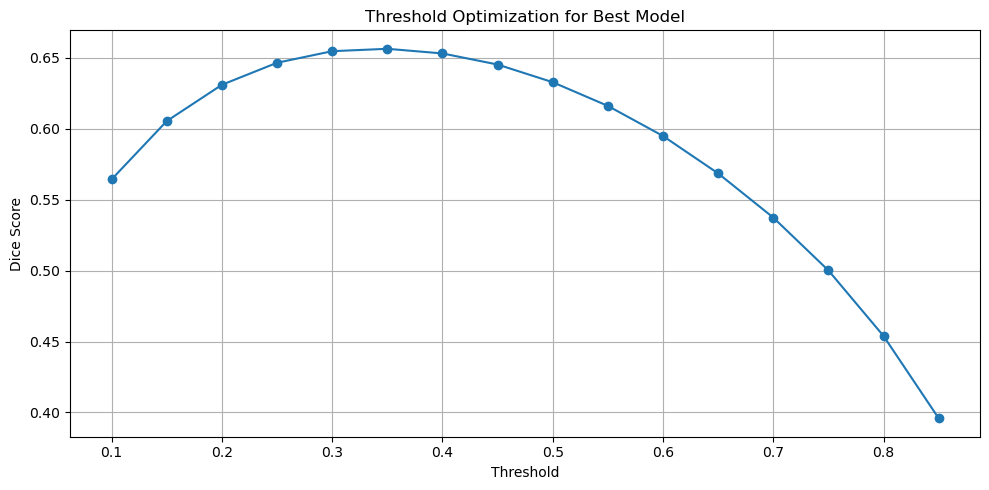

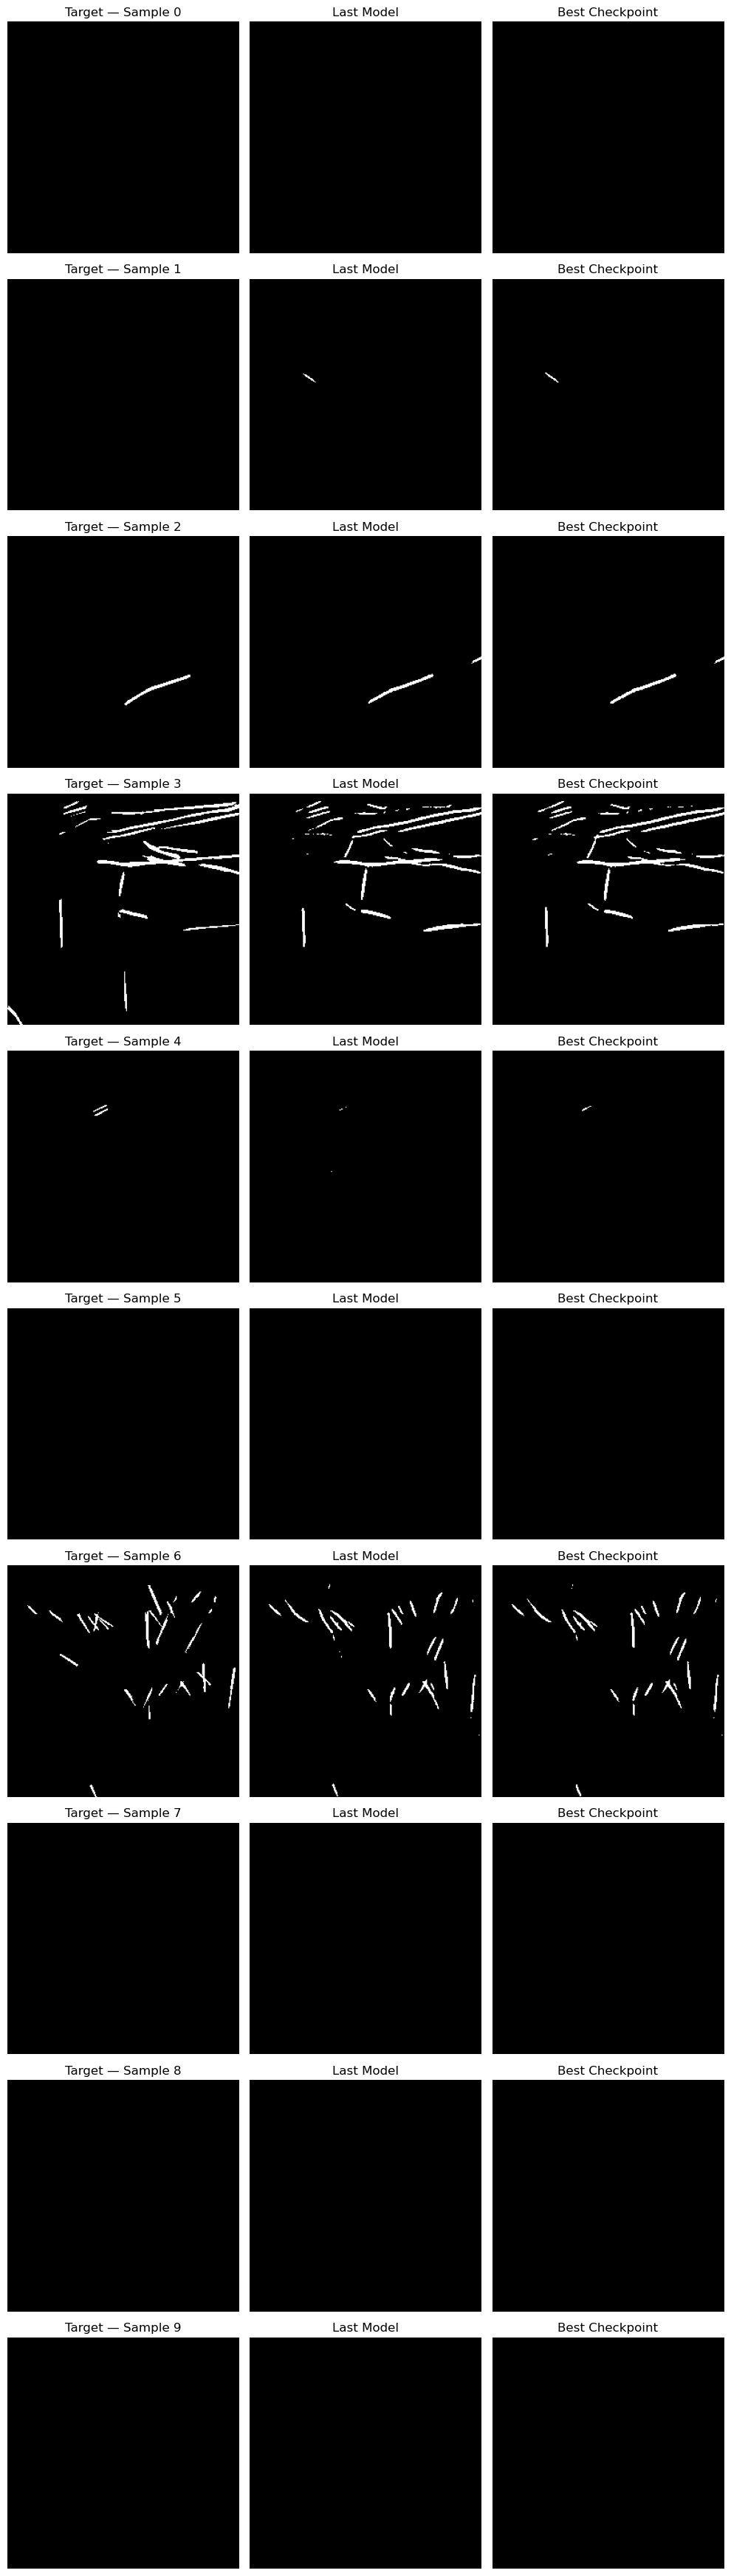

In [6]:
# Export metrics to CSV
metrics_df = pd.DataFrame(epoch_full_history)
metrics_df.to_csv(os.path.join(OUTPUT_PATH, "training_validation_metrics.csv"), index=False)
print(f"Saved metrics to {os.path.join(OUTPUT_PATH, 'training_validation_metrics.csv')}")

best_checkpoint_path = os.path.join(OUTPUT_PATH, "best_checkpoint.pth")
last_checkpoint_path = os.path.join(OUTPUT_PATH, "last_checkpoint.pth")
best_checkpoint = torch.load(best_checkpoint_path, map_location=device, weights_only=False)
last_checkpoint = torch.load(last_checkpoint_path, map_location=device, weights_only=False)


if PLOT_OUTPUT:

    epochs_range = range(1, MAX_EPOCHS + 1)

    # Training Loss
    plt.figure(figsize=(10, 5))
    plt.plot(epochs_range, weighted_loss_history, marker='o')
    plt.title('Training Loss History')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.grid(True)
    plt.gca().xaxis.set_major_locator(ticker.MaxNLocator(integer=True))
    plt.savefig(os.path.join(OUTPUT_PATH, "loss_history.png"))
    plt.tight_layout()
    plt.show()
    plt.close()

    # Validation Dice
    plt.figure(figsize=(10, 5))
    plt.plot(epochs_range, validation_history["best_dice"], marker='o')
    plt.title('Validation Dice History')
    plt.xlabel('Epoch')
    plt.ylabel('Dice Score')
    plt.grid(True)
    plt.gca().xaxis.set_major_locator(ticker.MaxNLocator(integer=True))
    plt.savefig(os.path.join(OUTPUT_PATH, "validation_dice_history.png"))
    plt.tight_layout()
    plt.show()
    plt.close()

    # Learning Rate
    plt.figure(figsize=(10, 5))
    plt.plot(epochs_range, learning_rate_history, marker='o')
    plt.title('Learning Rate History')
    plt.xlabel('Epoch')
    plt.ylabel('Learning Rate')
    plt.grid(True)
    plt.gca().xaxis.set_major_locator(ticker.MaxNLocator(integer=True))
    plt.savefig(os.path.join(OUTPUT_PATH, "learning_rate_history.png"))
    plt.tight_layout()
    plt.show()
    plt.close()

    # False Positives / False Negatives
    plt.figure(figsize=(10, 5))
    plt.plot(epochs_range, validation_history["false_positives"], marker='o', label='False Positives')
    plt.plot(epochs_range, validation_history["false_negatives"], marker='o', label='False Negatives')
    plt.title('Validation Error Metrics History')
    plt.xlabel('Epoch')
    plt.ylabel('Count')
    plt.legend()
    plt.grid(True)
    plt.gca().xaxis.set_major_locator(ticker.MaxNLocator(integer=True))
    plt.savefig(os.path.join(OUTPUT_PATH, "false_positives_negatives_history.png"))
    plt.tight_layout()
    plt.show()
    plt.close()

    # Precision / Recall
    plt.figure(figsize=(10, 5))
    plt.plot(epochs_range, validation_history["precision"], marker='o', label='Precision')
    plt.plot(epochs_range, validation_history["recall"], marker='o', label='Recall')
    plt.title('Validation Precision and Recall History')
    plt.xlabel('Epoch')
    plt.ylabel('Score')
    plt.legend()
    plt.grid(True)
    plt.gca().xaxis.set_major_locator(ticker.MaxNLocator(integer=True))
    plt.savefig(os.path.join(OUTPUT_PATH, "precision_recall_history.png"))
    plt.tight_layout()
    plt.show()
    plt.close()

    # Last Model Threshold Optimization
    df_last = metrics_df[metrics_df["epoch"] == MAX_EPOCHS]
    plt.figure(figsize=(10, 5))
    plt.plot(THRESHOLD_RANGE, df_last["dice"], marker='o',)
    plt.title('Threshold Optimization for Last Model')
    plt.xlabel('Threshold')
    plt.ylabel('Dice Score')
    plt.grid(True)
    plt.savefig(os.path.join(OUTPUT_PATH, "last_threshold_optimization.png"))
    plt.tight_layout()
    plt.show()
    plt.close()

    # Best Model Threshold Optimization
    df_best = metrics_df[metrics_df["epoch"] == best_epoch]
    plt.figure(figsize=(10, 5))
    plt.plot(THRESHOLD_RANGE, df_best["dice"], marker='o',)
    plt.title('Threshold Optimization for Best Model')
    plt.xlabel('Threshold')
    plt.ylabel('Dice Score')
    plt.grid(True)
    plt.savefig(os.path.join(OUTPUT_PATH, "best_threshold_optimization.png"))
    plt.tight_layout()
    plt.show()
    plt.close()

    # Comparison of Last and Best Model Predictions
    model.load_state_dict(last_checkpoint['model_state_dict'])

    # Starting with the last model
    model.eval()

    selected_indices = list(range(min(10, len(val_dataset))))
    last_preds_samples = []
    sample_images = []
    sample_targets = []

    last_best_threshold = df_last.loc[df_last["dice"].idxmax()]["threshold"]

    with torch.no_grad():
        for idx in selected_indices:
            img, target_mask = val_dataset[idx]
            sample_images.append(img)
            sample_targets.append(target_mask.squeeze().numpy())
            
            pred = model(img.unsqueeze(0).to(device))
            last_preds_samples.append((torch.sigmoid(pred).squeeze().cpu().numpy() > last_best_threshold))

    # Best Model
    model.load_state_dict(best_checkpoint['model_state_dict'])

    best_preds_samples = []

    with torch.no_grad():
        for img in sample_images:
            pred = model(img.unsqueeze(0).to(device))
            best_preds_samples.append((torch.sigmoid(pred).squeeze().cpu().numpy() > best_threshold))

    # Plot
    n_samples = len(sample_images)
    fig, axes = plt.subplots(n_samples, 3, figsize=(10, 3.5 * n_samples))
    axes = np.atleast_2d(axes)


    for row in range(n_samples):
        # Ground Truth
        axes[row, 0].imshow(sample_targets[row], cmap="gray")
        axes[row, 0].set_title(f"Target — Sample {selected_indices[row]}")
        axes[row, 0].axis("off")

        # Last Model
        axes[row, 1].imshow(last_preds_samples[row], cmap="gray")
        axes[row, 1].set_title(f"Last Model")
        axes[row, 1].axis("off")

        # Best Model
        axes[row, 2].imshow(best_preds_samples[row], cmap="gray")
        axes[row, 2].set_title(f"Best Checkpoint")
        axes[row, 2].axis("off")

    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_PATH, "prediction_examples_comparison.png"))
    plt.show()
    plt.close()


TESTING AND SUBMISSION

In [7]:
test_ids = []
test_preds = []

with torch.no_grad():
    for images, image_ids in test_loader:
        images = images.to(device)
        
        outputs = model(images)
        probs_original = torch.sigmoid(outputs)
        probs_hflip = torch.flip(torch.sigmoid(model(torch.flip(images, dims=[3]))), dims=[3])
        probs_vflip = torch.flip(torch.sigmoid(model(torch.flip(images, dims=[2]))), dims=[2])
        probs = (probs_original + probs_hflip + probs_vflip) / 3.0
        preds = (probs > best_threshold).cpu().numpy()
        
        # Remove the channel dimension so masks are shape (256, 256)
        preds = np.squeeze(preds, axis=1) 
        
        test_preds.append(preds)
        test_ids.extend(image_ids)

test_preds = np.concatenate(test_preds, axis=0)
submission_path = os.path.join(OUTPUT_PATH, "submission.csv")
write_submission(record_ids=test_ids, masks=test_preds, path=submission_path)

print(f"Submission saved successfully to: {submission_path}")

Submission saved successfully to: /home/dinis/Desktop/Universidade/Cadeiras/Ano4-Q1/AE4353 Artificial Intelligence for Aerospace Control and Operations/Competition/Output/model01_new_scheduler_2/submission.csv
